# 01_2 PCA of the tile embeddings: how much dimensionality does UNI2-h need?

**Overview.** This notebook studies the principal component analysis (PCA) of the 1536-dimensional UNI2-h tile embeddings saved by `01_1_wsi_to_vectors.ipynb`. It asks how reducing the dimension affects (1) the explained variance, (2) the eigenvalue spectrum and its effective rank, (3) the reconstruction of held-out embeddings and (4) the preservation of the cosine neighbourhood structure of the tiles. The results guide the choice of a dimension for later work; no synthetic data are generated and no classifier is trained here.

One PCA is fitted on a slide-balanced sample of tiles from the official **Training** slides only and is reused for every candidate dimension (the first *d* components). It is evaluated on **Validation** slides of patients that do not appear in Training. The official Testing slides are never used for fitting or evaluation; they are only transformed in the last section, when the reduced embeddings are stored.

The reduced vectors are written to `PCA_OUTPUT_DIR/pca_<d>/UNI2-h/<slide>.pt` (same keys as the original files), with the fitted PCA (`pca_model.pt`) and the configuration (`metadata.json`). The original files are only read. No figure or report is exported.

**PCA per cross-validation fold (`PER_FOLD`, section 12).** The PCA above is fitted on all official Training slides. Notebooks 02_3 and 02_4 pool the Training and Validation slides and cross-validate over patient-grouped folds, so the held-out slides of a fold include Training slides that this PCA has seen; the cross-validation score of a model built on its output is then optimistic. With `PER_FOLD = True` section 12 fits one PCA per fold on the fit slides of that fold only (not on its early-stopping or held-out slides, and not on the official Testing slides), with the folds of 02_3 and 02_4 (`N_FOLDS`, `CV_SEED`, `EARLY_STOP_FRACTION` and the three-class stratification), and transforms the slides of the fold and the Testing slides with it. The files are written to `PCA_OUTPUT_DIR/cv_fold_<k>/pca_<d>/UNI2-h/` with the stored set `Training` (fit), `Validation` (early stopping), `HeldOut` (held-out) or `Testing` (official Testing), and the metadata records the fold and its slide lists, which the later notebooks compare with their own folds. The global PCA and its analysis (sections 3 to 11) are not changed; set `OVERWRITE = False` to keep their files.

```mermaid
flowchart TD
    FEAT[("level_1/UNI2-h/<br/>one .pt file per slide (from 01_1)")] --> SAMP["3. split_fit_eval + sample_tiles"]
    SAMP --> FIT["4. fit_pca<br/>Training sample only"]
    FIT --> VAR["5. variance_table"]
    FIT --> SPEC["6. spectrum_stats"]
    FIT --> REC["7. reconstruction_metrics<br/>Validation sample"]
    FIT --> NB["8. neighbour_preservation<br/>cosine, exact top-k"]
    VAR --> CMP["9. final_comparison + recommend_dimensions"]
    REC --> CMP
    NB --> CMP
    FIT --> SAVE["10. save_pca_embeddings"]
    SAVE --> OUT[("pca_d/UNI2-h/<br/>pca_model.pt, metadata.json")]
    FEAT --> FOLDPCA["12. cv_folds_for_features + fit_fold_pca_embeddings<br/>PER_FOLD: one PCA per fold, fit slides only"]
    FOLDPCA --> FOUT[("cv_fold_k/pca_d/UNI2-h/<br/>pca_model.pt, metadata.json with the fold")]
```

## 1. Setup

The environment is recorded so the run can be reproduced.

In [1]:
# STEP 1: Standard-library imports and general-purpose third-party libraries
import sys
import matplotlib
import numpy as np
import pandas as pd
import scipy
import sklearn
import torch

# STEP 2: Print library versions for reproducibility
print('System Version:', sys.version)
print('PyTorch version:', torch.__version__)
print('Numpy version:', np.__version__)
print('Pandas version:', pd.__version__)
print('SciPy version:', scipy.__version__)
print('scikit-learn version:', sklearn.__version__)
print('Matplotlib version:', matplotlib.__version__)

System Version: 3.14.7 (main, Aug 10 2026, 07:46:56) [GCC 16.1.1 20260728]
PyTorch version: 2.15.0+cu132
Numpy version: 2.5.4
Pandas version: 3.1.1
SciPy version: 1.18.1
scikit-learn version: 1.9.1
Matplotlib version: 3.11.2


The project's own building blocks are imported.

In [2]:
# STEP 1: Standard-library imports
import json
from pathlib import Path

# STEP 2: Import this project's own building blocks
from utils.dataset_overview import build_slide_table
from utils.device import get_device
from utils.mil_cv import fold_summary
from utils.mil_train import set_seed
from utils.per_fold import check_fold_metadata, cv_folds_for_features, fold_pca_dir
from utils.pca_analysis import (final_comparison, fit_fold_pca_embeddings, fit_pca, neighbour_preservation, plot_neighbours, plot_reconstruction,
                                plot_spectrum, plot_variance, recommend_dimensions, reconstruction_metrics, sample_tiles,
                                sampling_stats, save_pca_embeddings, spectrum_stats, split_fit_eval, timed, variance_table)

## 2. Constants

`PER_FOLD`, `FOLD_DIMENSIONS`, `N_FOLDS`, `CV_SEED` and `EARLY_STOP_FRACTION` belong to section 12: the dimensions that are stored for every fold and the cross-validation settings, which must equal those of notebooks 02_3 and 02_4 (the CV seed is `0` there, whereas `SEED` is the seed of the PCA sampling); `THREE_MAPPING` is the class grouping that stratifies the folds. The rest of this section is unchanged.

Every setting is defined here. `PCA_DIMENSIONS` are the candidate dimensions; the PCA is fitted once with `max(PCA_DIMENSIONS)` components. The sample for fitting is set by `MAX_TILES_PER_SLIDE` and `MAX_FIT_TILES` (`MAX_EVAL_TILES` for the held-out sample); with `STRATIFY_BY_LABEL` the budget is first shared equally among the classes. The neighbourhood analysis uses `N_QUERIES` query tiles and the reference population of the held-out sample, in the space given by `NEIGHBOUR_SPACE`. The PCA is not whitened (`WHITEN`). `SAVE_PCA_EMBEDDINGS` turns the storage of section 10 on; existing outputs are not replaced unless `OVERWRITE` is set.

In [3]:
# Major variables
FEATURES_DIR = Path('/mnt/Scratch/phd_streamembed_features/level_1')    # STEP 1: Folder with one subfolder of .pt files per model (from 01_1)
MODEL_NAME = 'UNI2-h'                                                   # STEP 2: Subfolder with the per-slide features
LABELS_FILE = Path('labels/BRACS.xlsx')                                 # STEP 3: Slide labels, patients and official split
PCA_DIMENSIONS = [256]                                                  # STEP 4: Candidate dimensions
SEED = 42                                                               # STEP 5: Seed of every random choice
MAX_TILES_PER_SLIDE, MAX_FIT_TILES, MAX_EVAL_TILES = 500, 200_000, 100_000   # STEP 6: Tiles per slide; total tiles to fit the PCA; total held-out tiles
STRATIFY_BY_LABEL = False                                               # STEP 7: Share the sampling budget equally among the classes
SOLVER, BATCH_SIZE = 'randomized', 20_000                               # STEP 8: 'randomized' or 'incremental'; batch size of the incremental solver
WHITEN = False                                                          # STEP 9: Divide stored scores by the square root of their variance (analysis is never whitened)
N_QUERIES, N_PAIRS, NEIGHBOUR_SPACE = 5000, 200_000, 'scores'           # STEP 10: Query tiles; random pairs for Spearman; 'scores' or 'reconstructed'
SAVE_PCA_EMBEDDINGS = True                                              # STEP 11: Store the reduced embeddings (section 10)
PCA_OUTPUT_DIR = Path('/mnt/Scratch/phd_streamembed_features')          # STEP 12: Receives pca_<d>/<MODEL_NAME>/<slide>.pt
OVERWRITE = True                                                        # STEP 13: Replace existing PCA outputs (default: refuse)
CACHE_FILE = Path('outputs/01_2_pca/neighbours_cache.pt')               # STEP 14: Cache of the original-space neighbours (None = no cache)
PER_FOLD, FOLD_DIMENSIONS = True, [256, 512]                           # STEP 15: One PCA per cross-validation fold (section 12) and the dimensions stored for each
N_FOLDS, CV_SEED, EARLY_STOP_FRACTION = 5, 0, 0.2                       # STEP 16: Folds, seed and early-stopping share of 02_3 / 02_4 (the CV seed is not SEED)
THREE_MAPPING = {'N': 'Non-cancer', 'PB': 'Non-cancer', 'UDH': 'Non-cancer', 'FEA': 'Non-cancer',
                 'ADH': 'Non-invasive atypia/neoplasia', 'DCIS': 'Non-invasive atypia/neoplasia', 'IC': 'Invasive carcinoma'}   # STEP 17: BRACS class -> group that stratifies the folds (as 02_3 / 02_4)
set_seed(SEED)
device = get_device()
print('Device:', device)

Device: cuda


## 3. Data and sampling

The slide table gives the class, patient and official set of each slide. The Training slides are the source of the fitting sample and the Validation slides, minus patients that also have Training slides (patient 67), the source of the held-out sample. Each slide contributes at most `MAX_TILES_PER_SLIDE` tiles and the quotas are reduced equally when the total exceeds the budget, so large slides do not dominate. Only the sampled rows are read from the memory-mapped files.

In [4]:
# STEP 1: Slide table and the patient-disjoint split
table = build_slide_table(LABELS_FILE)
labels = dict(zip(table['slide'], table['label'].astype(str)))
split = split_fit_eval(table)
print({k: len(v) for k, v in split.items()})

# STEP 2: Sample the tiles
with timed('sampling'):
    fit_sample = sample_tiles(FEATURES_DIR, MODEL_NAME, split['fit'], labels, MAX_TILES_PER_SLIDE, MAX_FIT_TILES, SEED, STRATIFY_BY_LABEL)
    eval_sample = sample_tiles(FEATURES_DIR, MODEL_NAME, split['eval'], labels, MAX_TILES_PER_SLIDE, MAX_EVAL_TILES, SEED, STRATIFY_BY_LABEL)

# STEP 3: Sampling statistics
fit_stats, eval_stats = sampling_stats(fit_sample, table), sampling_stats(eval_sample, table)
print('Fit sample:', fit_sample['X'].shape, '| missing files:', len(fit_sample['missing']))
print('Held-out sample:', eval_sample['X'].shape, '| missing files:', len(eval_sample['missing']))
display(fit_stats['per_class'])
display(eval_stats['per_class'])
display(fit_stats['per_slide']['sampled'].describe().to_frame('tiles per fit slide').T)

{'fit': 395, 'eval': 63, 'excluded': 2}
[sampling] 0.8 s
Fit sample: (196101, 1536) | missing files: 0
Held-out sample: (30950, 1536) | missing files: 0


,label,slides,patients,available,sampled,share
0,N,27,18,139115,12264,0.062539
1,PB,120,66,1471945,59837,0.305134
2,UDH,56,34,560306,28000,0.142784
3,FEA,24,14,348670,12000,0.061193
4,ADH,28,16,291515,14000,0.071392
5,DCIS,40,21,468547,20000,0.101988
6,IC,100,53,1111056,50000,0.254971


,label,slides,patients,available,sampled,share
0,N,8,4,61580,3941,0.127334
1,PB,11,7,81298,5500,0.177706
2,UDH,9,6,57208,4009,0.129532
3,FEA,6,6,41051,3000,0.096931
4,ADH,8,6,66748,4000,0.129241
5,DCIS,9,6,108525,4500,0.145396
6,IC,12,5,135967,6000,0.193861


,count,mean,std,min,25%,50%,75%,max
tiles per fit slide,395.0,496.458228,33.98141,26.0,500.0,500.0,500.0,500.0


## 4. PCA fit

One PCA is fitted on the Training sample with enough components for every candidate dimension. The solver is randomised (or incremental, set in the constants); the embeddings are centred with the training mean and not whitened, so the components are orthonormal axes and the scores of dimension *d* are the first *d* scores. Candidate dimensions above the number of fitted components are dropped with a message.

In [5]:
# STEP 1: Fit once, reuse for every dimension
with timed('PCA fit'):
    pca, dims = fit_pca(fit_sample['X'], PCA_DIMENSIONS, SOLVER, BATCH_SIZE, SEED)
print('Fitted components:', pca.n_components_, '| usable dimensions:', dims)

# STEP 2: Basic checks
C = pca.components_
assert np.allclose(C[:64] @ C[:64].T, np.eye(min(64, len(C))), atol=1e-3), 'components are not orthonormal'

[PCA fit] 3.8 s
Fitted components: 256 | usable dimensions: [256]


## 5. Explained variance

The explained variance ratio of component *i* is its eigenvalue divided by the total variance of the training sample. The table gives the cumulative variance at each candidate dimension and the number of components needed to reach 90, 95, 99 and 99.5 % (NaN when the fitted components do not reach the level). Explained variance measures retained energy only; it is not used alone to choose a dimension.

,dimensions,explained_variance,residual
0,256,0.804254,0.195746


,threshold,components
0,0.900,NaN
1,0.950,NaN
2,0.990,NaN
3,0.995,NaN


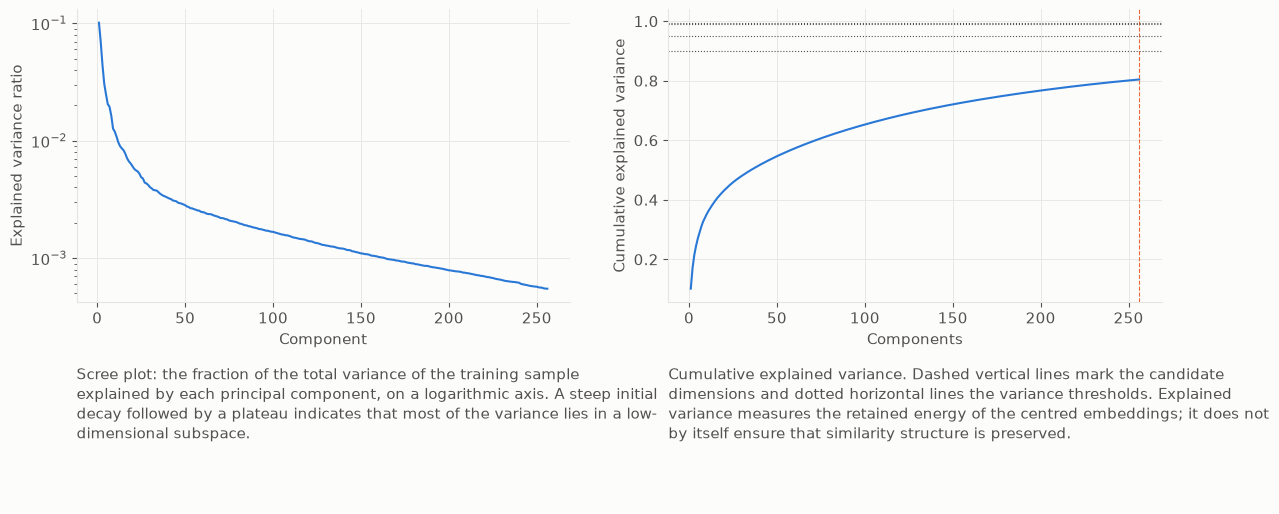

In [6]:
# STEP 1: Tables
var_by_dim, var_by_threshold = variance_table(pca, dims)
display(var_by_dim)
display(var_by_threshold)

# STEP 2: Scree and cumulative plots
_ = plot_variance(pca, dims)

## 6. Eigenvalue spectrum and effective rank

The effective rank is the exponential of the Shannon entropy of the normalised eigenvalues (Roy and Vetterli, 2007). When fewer than 1536 components are fitted, the value is computed on the kept spectrum, is labelled truncated, and is bracketed by two bounds that use the variance left in the unfitted tail. Elbows are candidate dimensions from the shape of the log spectrum, not a selection rule.

Effective rank (truncated): 91.1
Bounds for the full spectrum: 61.8 - 250.6
Elbows: {'chord': 32, 'curvature': 3}


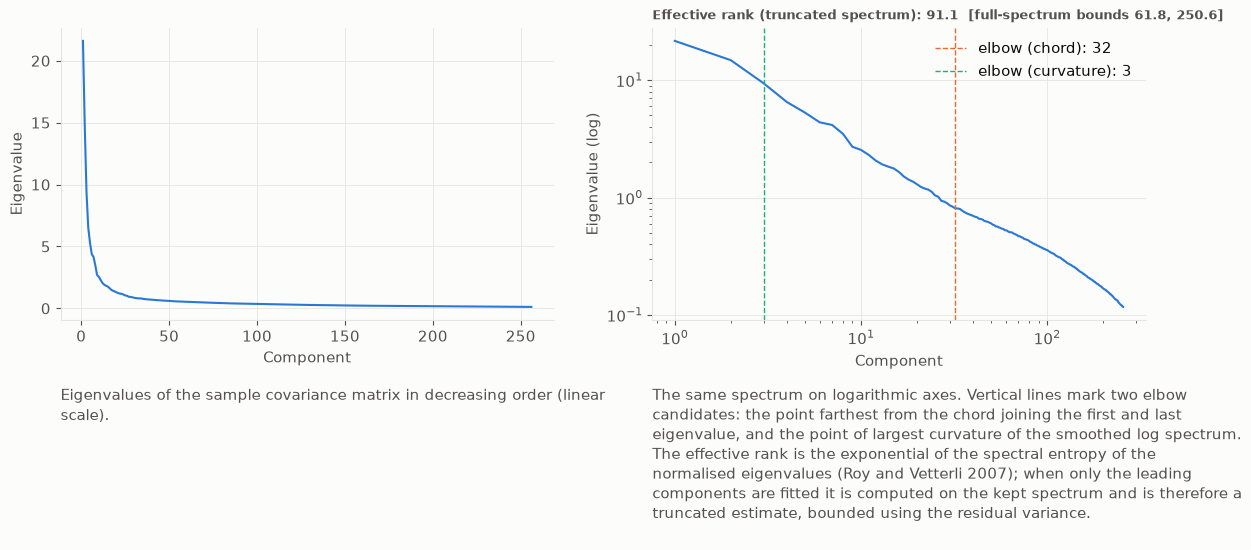

In [7]:
# STEP 1: Spectrum statistics
spec = spectrum_stats(pca)
print(f"Effective rank{' (truncated)' if spec['truncated'] else ''}: {spec['effective_rank']:.1f}")
print('Bounds for the full spectrum: %.1f - %.1f' % spec['effective_rank_bounds'])
print('Elbows:', spec['elbows'])

# STEP 2: Plot
_ = plot_spectrum(spec)

## 7. Reconstruction error

Held-out embeddings are projected, reconstructed in the original 1536-dimensional space from the first *d* scores and compared with the originals. MSE is the mean squared error per coordinate; NMSE divides the total squared error by the total squared deviation of the held-out embeddings from the training mean (NMSE = 1 means no better than the mean vector); cosine is computed between each embedding and its reconstruction. The per-tile error is the mean squared error over the coordinates of one tile.

[reconstruction] 0.3 s


,dimensions,mse,nmse,cosine,error_mean,error_median,error_std,error_p95,error_p99
0,256,0.030608,0.212981,0.913731,0.030608,0.027499,0.013226,0.055601,0.078438


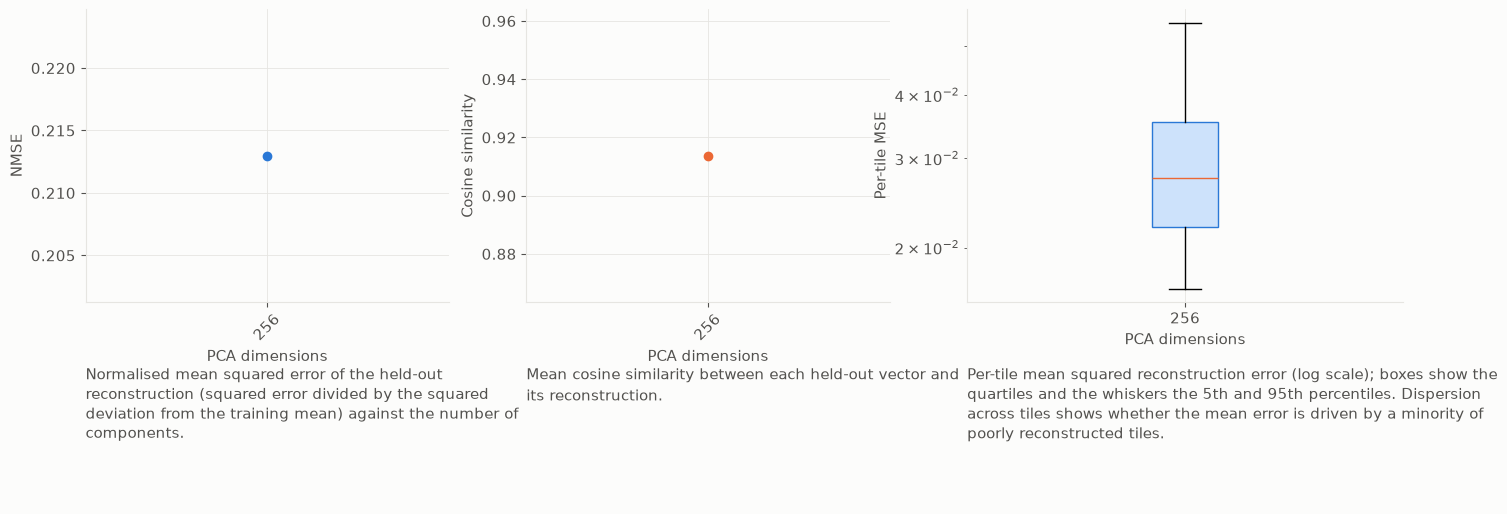

In [8]:
# STEP 1: Metrics for every dimension from one projection
with timed('reconstruction'):
    recon, recon_tiles = reconstruction_metrics(pca, eval_sample['X'], dims)
display(recon)

# STEP 2: Plots
_ = plot_reconstruction(recon, recon_tiles)

## 8. Neighbourhood preservation

For `N_QUERIES` random held-out tiles, the nearest neighbours in the original space (cosine, exact search over the whole held-out reference sample, the query itself excluded) are compared with those in each reduced space. The same queries and reference population are used for every dimension and the original-space neighbours are cached. Recall@k is the mean fraction of the k original neighbours recovered; the overlap is the number of shared neighbours among the top 10; Spearman is the rank correlation of cosine similarity over random tile pairs. Tiles of the same slide are often mutual neighbours, so the per-slide and per-class breakdowns are shown. FAISS is not installed; an exact chunked search in torch is used instead.

[neighbour preservation] 0.5 s


,dimensions,recall@10,recall@20,overlap_mean,overlap_median,spearman
0,256,0.7368,0.75241,7.368,8.0,0.620871


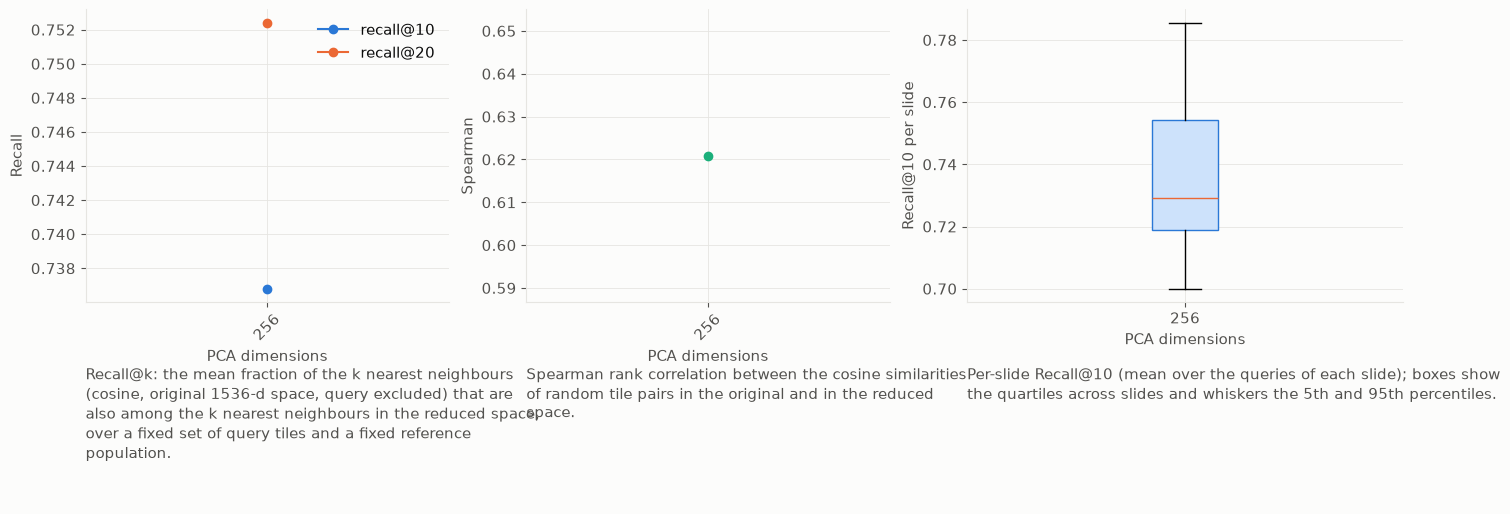

dimensions,256
label,
ADH,0.713366
DCIS,0.724414
FEA,0.730169
IC,0.732696
N,0.739590
PB,0.752872
UDH,0.757380


In [9]:
# STEP 1: Reference labels and the neighbourhood analysis
ref_label = np.array([labels[eval_sample['names'][i]] for i in eval_sample['slide']])
with timed('neighbour preservation'):
    neigh = neighbour_preservation(eval_sample['X'], pca, dims, eval_sample['slide'], ref_label, N_QUERIES, (10, 20),
                                   N_PAIRS, SEED, NEIGHBOUR_SPACE, cache_path=CACHE_FILE, device=device)
display(neigh['summary'])

# STEP 2: Plots and breakdowns
_ = plot_neighbours(neigh)
display(neigh['per_label'].pivot(index='label', columns='dimensions', values='recall@10'))

## 9. Final comparison

One table joins the metrics of all candidate dimensions. The recommended dimensions are the smallest ones that reach a given Recall@10 (the neighbourhood structure is what the later work depends on), so the choice does not rest on explained variance alone. Read the interpretation below against the numbers of your own run.

In [10]:
# STEP 1: Comparison table and candidate dimensions
comparison = final_comparison(var_by_dim, recon, neigh['summary'])
display(comparison)
recommended = recommend_dimensions(comparison, recall_targets=(0.80, 0.90, 0.95))
display(recommended)

,Dimensions,Explained variance,NMSE,Cosine similarity,Recall@10,Recall@20,Spearman
0,256,0.804254,0.212981,0.913731,0.7368,0.75241,0.620871


,Recall@10 target,Dimensions
0,0.80,NaN
1,0.90,NaN
2,0.95,NaN


**Interpretation.** *(to be written after the run on the workstation: state the dimensions of `recommended`, the dimension where Recall@10 and NMSE flatten, and the effective rank, and name 2 to 3 promising dimensions for the synthetic embedding generation.)*

## 10. Storage of the reduced embeddings

The fitted PCA is applied, one slide at a time, to every labelled slide (Training, Validation and Testing; the PCA is never refitted) and the first *d* scores are written to `pca_<d>/UNI2-h/<slide>.pt`, keeping the tile order, coordinates and `tile_params` of the original file and adding `slide`, `label`, `patient`, `set`. `pca_model.pt` holds the mean, components and explained variance and `metadata.json` the configuration and the fit/held-out slide lists. Existing outputs are never replaced unless `OVERWRITE` is set, and nothing is written into the folder of the original embeddings.

In [11]:
# STEP 1: Configuration saved with the models
config = {'seed': SEED, 'solver': SOLVER, 'dimensions': dims, 'max_tiles_per_slide': MAX_TILES_PER_SLIDE,
          'max_fit_tiles': MAX_FIT_TILES, 'stratify_by_label': STRATIFY_BY_LABEL, 'fit_slides': fit_sample['names'],
          'eval_slides': eval_sample['names'], 'excluded_slides': split['excluded'], 'fit_tiles': int(len(fit_sample['X'])),
          'explained_variance_at_dims': dict(zip(dims, var_by_dim['explained_variance'])), 'features_dir': FEATURES_DIR}

# STEP 2: Save
if SAVE_PCA_EMBEDDINGS:
    with timed('storage'):
        saved = save_pca_embeddings(FEATURES_DIR, PCA_OUTPUT_DIR, MODEL_NAME, pca, dims, table, config, WHITEN, OVERWRITE)
    print(len(saved['saved']), 'slides saved;', len(saved['missing']), 'without a feature file')

[storage] 17.9 s
547 slides saved; 0 without a feature file


## 11. Validation checks

The saved files are reloaded for one slide and compared with a fresh projection of the original embeddings: shape, tile order, coordinates and values must agree, and the original file must be unchanged.

In [12]:
# STEP 1: Fit and held-out sets share no patient and exclude Testing
patients = table.set_index('slide')['patient']
sets = table.set_index('slide')['set']
assert not set(patients[fit_sample['names']]) & set(patients[eval_sample['names']])
assert not (sets[fit_sample['names'] + eval_sample['names']] == 'Testing').any()

# STEP 2: Reload one saved slide for the smallest and the largest dimension
if SAVE_PCA_EMBEDDINGS:
    slide = saved['saved'][0]
    original = torch.load(FEATURES_DIR / MODEL_NAME / f'{slide}.pt', weights_only=True, mmap=True)
    scores = (original['cls_features'].float().numpy() - pca.mean_) @ pca.components_.T
    if WHITEN:
        scores = scores / np.sqrt(pca.explained_variance_)
    for d in (dims[0], dims[-1]):
        reduced = torch.load(PCA_OUTPUT_DIR / f'pca_{d}' / MODEL_NAME / f'{slide}.pt', weights_only=True)
        assert reduced['cls_features'].shape == (len(original['cls_features']), d)
        assert torch.equal(reduced['coordinates'], original['coordinates'])
        assert np.allclose(reduced['cls_features'].numpy(), scores[:, :d], atol=1e-3)
    print('Saved files agree with a fresh projection of', slide)

Saved files agree with a fresh projection of BRACS_264


## 12. PCA per cross-validation fold (`PER_FOLD`)

The folds are those of notebooks 02_3 and 02_4: the Training and Validation slides with usable vectors are relabelled to the three classes of `THREE_MAPPING` and split by `make_cv_folds` into patient-grouped, class-stratified folds with `N_FOLDS`, `CV_SEED` and `EARLY_STOP_FRACTION`. For every fold, a slide-balanced sample of the tiles of the **fit slides only** is drawn (the quotas of sections 3 and 4) and one PCA is fitted with the largest of `FOLD_DIMENSIONS`; the same PCA gives the stored dimensions (the first $d$ components). The slides of the fold (fit, early-stopping and held-out) and the official Testing slides are then transformed with it and written to `PCA_OUTPUT_DIR/cv_fold_<k>/pca_<d>/UNI2-h/`. The fit slides of a fold are a subset of the official Training and Validation slides, so the explained variance differs slightly between folds and from the global PCA; the table gives it for each fold. Without `PER_FOLD` nothing is run.

In [13]:
# STEP 1: The folds of 02_3 / 02_4 (slides with usable vectors, three-class stratification)
if PER_FOLD:
    folds, _ = cv_folds_for_features(FEATURES_DIR, MODEL_NAME, LABELS_FILE, THREE_MAPPING, N_FOLDS, CV_SEED, EARLY_STOP_FRACTION)
    display(fold_summary(folds, list(dict.fromkeys(THREE_MAPPING.values()))))

    # STEP 2: One PCA per fold on its fit slides, and the transformed slides of the fold
    with timed('PCA per fold'):
        fold_pca = fit_fold_pca_embeddings(FEATURES_DIR, PCA_OUTPUT_DIR, MODEL_NAME, folds, FOLD_DIMENSIONS, MAX_TILES_PER_SLIDE, MAX_FIT_TILES, SEED, SOLVER, BATCH_SIZE,
                                           WHITEN, OVERWRITE, STRATIFY_BY_LABEL, labels)
    display(fold_pca.round(4))
else:
    print('PER_FOLD is False: nothing to run.')

,fold,fit,early stopping,held out,held-out patients,Non-cancer,Non-invasive atypia/neoplasia,Invasive carcinoma
0,0,293,74,93,34,53,17,23
1,1,295,72,93,33,53,17,23
2,2,295,73,92,33,53,17,22
3,3,294,75,91,29,52,17,22
4,4,297,72,91,29,52,17,22


[PCA per fold] 159.7 s


,fold,fit slides,fit tiles,explained variance 256,explained variance 512
0,0,293,146278,0.8068,0.9020
1,1,295,146575,0.8101,0.9037
2,2,295,146254,0.8091,0.9031
3,3,294,145110,0.8104,0.9037
4,4,297,146714,0.8079,0.9024


### 12.1 Validation checks of the fold PCA

For every fold the fit slides recorded in the metadata must be the fit slides of the fold, share no patient with its early-stopping or held-out slides and include no official Testing slide; the folds must agree with `metadata.json` (`check_fold_metadata`, which the later notebooks run too). One held-out slide per fold is reloaded and compared with a fresh projection of its original vectors with the PCA of that fold.

In [14]:
# STEP 1: The recorded folds, and no leak between fit, early-stopping, held-out and Testing slides
if PER_FOLD:
    check_fold_metadata(folds, PCA_OUTPUT_DIR, FOLD_DIMENSIONS[0])
    patient_of, testing = dict(zip(table['slide'], table['patient'])), set(table.loc[table['set'] == 'Testing', 'slide'])
    for k, fold in enumerate(folds):
        folder = fold_pca_dir(PCA_OUTPUT_DIR, k, FOLD_DIMENSIONS[0])
        meta = json.loads((folder / 'metadata.json').read_text())
        assert set(meta['fit_slides']) == set(fold['fit']) and not set(meta['fit_slides']) & testing
        assert not {patient_of[s] for s in fold['fit']} & {patient_of[s] for s in fold['stop'] + fold['held']}

        # STEP 2: One held-out slide against a fresh projection with the PCA of the fold
        model = torch.load(folder / 'pca_model.pt', weights_only=True)
        slide = fold['held'][0]
        original = torch.load(FEATURES_DIR / MODEL_NAME / f'{slide}.pt', weights_only=True, mmap=True)
        scores = (original['cls_features'].float().numpy() - model['mean'].numpy()) @ model['components'].numpy().T
        reduced = torch.load(folder / MODEL_NAME / f'{slide}.pt', weights_only=True)
        assert reduced['set'] == 'HeldOut' and reduced['cls_features'].shape == scores.shape
        assert np.allclose(reduced['cls_features'].numpy(), scores, atol=1e-3)
    print('All', len(folds), 'folds passed the checks.')
else:
    print('PER_FOLD is False: nothing to check.')

All 5 folds passed the checks.
